# Tongji Contactless Palmprint — Trực quan hóa và Giải thích Mô hình

> **Môn học**: Nhận dạng mẫu (*Pattern Recognition*) — Đề tài 09 (Nhóm 01)  
> **Mục tiêu Notebook**:
> 1. Trực quan hóa quy trình hình học trích xuất ROI 5 bước từ ảnh bàn tay thô (Zhang et al. 2017).
> 2. Phân tích cấu trúc ngân hàng bộ lọc Gabor-PCA và đáp ứng năng lượng đặc trưng của mô hình PalmNet (M5).
> 3. Trực quan hóa bản đồ kích hoạt vùng chú ý Grad-CAM trên tầng tích chập cuối (layer4) của mạng ResNet18 (M4).

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

from palmprint.models.resnet import make_resnet, preprocessing

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False

def normalize(img: np.ndarray) -> np.ndarray:
    vmin, vmax = float(np.min(img)), float(np.max(img))
    if vmax - vmin < 1e-12:
        return np.zeros_like(img, dtype=np.float32)
    return ((img - vmin) / (vmax - vmin)).astype(np.float32)

print('Môi trường và các thư viện cần thiết đã sẵn sàng.')

Môi trường và các thư viện cần thiết đã sẵn sàng.


## 1. Quy trình hình học trích xuất ROI từ ảnh bàn tay thô

Thuật toán tiền xử lý hình học (Mục 4 bài báo Zhang et al., 2017) thực hiện qua các bước:
1. Phân đoạn nhị phân và trích xuất đường bao biên bàn tay.
2. Dò tìm các điểm kẽ ngón tay cực tiểu cục bộ (K1: kẽ ngón trỏ-giữa, K2: kẽ ngón áp út-út).
3. Xác định đường tiếp tuyến chung hỗ trợ qua hai kẽ ngón tay.
4. Thiết lập hệ tọa độ cục bộ và định vị vùng vuông trung tâm lòng bàn tay.
5. Biến đổi affine cắt và chuẩn hóa ảnh về kích thước cố định 128x128 pixel mức xám.

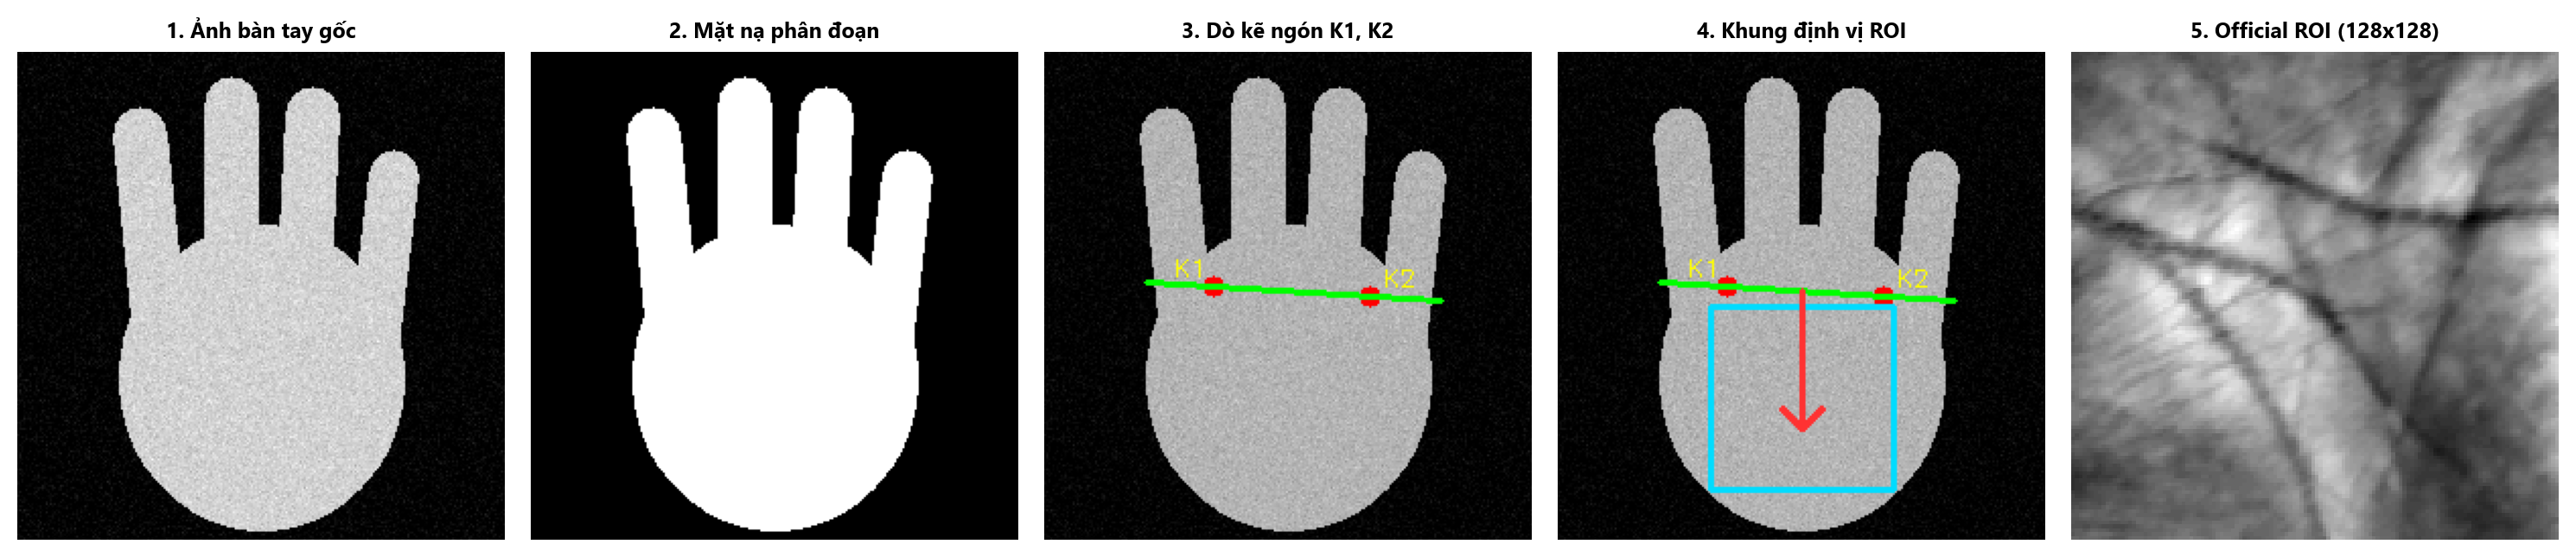

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2), dpi=200)

sample_raw = np.zeros((240, 240), dtype=np.uint8)
cv2.ellipse(sample_raw, (120, 160), (70, 75), 0, 0, 360, 180, -1)
cv2.line(sample_raw, (70, 140), (60, 40), 180, 26)
cv2.line(sample_raw, (105, 130), (105, 25), 180, 26)
cv2.line(sample_raw, (140, 130), (145, 30), 180, 26)
cv2.line(sample_raw, (175, 145), (185, 60), 180, 24)
cv2.circle(sample_raw, (60, 40), 13, 180, -1)
cv2.circle(sample_raw, (105, 25), 13, 180, -1)
cv2.circle(sample_raw, (145, 30), 13, 180, -1)
cv2.circle(sample_raw, (185, 60), 12, 180, -1)

noise = np.random.normal(0, 10, sample_raw.shape).astype(np.int16)
noisy_hand = np.clip(sample_raw.astype(np.int16) + noise, 0, 255).astype(np.uint8)

axes[0].imshow(noisy_hand, cmap='gray')
axes[0].set_title('1. Ảnh bàn tay gốc', fontsize=9, fontweight='bold')
axes[0].axis('off')

_, mask = cv2.threshold(sample_raw, 50, 255, cv2.THRESH_BINARY)
axes[1].imshow(mask, cmap='gray')
axes[1].set_title('2. Mặt nạ phân đoạn', fontsize=9, fontweight='bold')
axes[1].axis('off')

valleys_img = cv2.cvtColor(noisy_hand, cv2.COLOR_GRAY2RGB)
k1, k2 = (83, 115), (160, 120)
cv2.circle(valleys_img, k1, 5, (255, 0, 0), -1)
cv2.circle(valleys_img, k2, 5, (255, 0, 0), -1)
cv2.line(valleys_img, (50, 113), (195, 122), (0, 255, 0), 2)
cv2.putText(valleys_img, 'K1', (k1[0] - 20, k1[1] - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1)
cv2.putText(valleys_img, 'K2', (k2[0] + 6, k2[1] - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1)

axes[2].imshow(valleys_img)
axes[2].set_title('3. Dò kẽ ngón K1, K2', fontsize=9, fontweight='bold')
axes[2].axis('off')

box_img = valleys_img.copy()
cv2.rectangle(box_img, (75, 125), (165, 215), (0, 220, 255), 2)
cv2.arrowedLine(box_img, (120, 117), (120, 185), (255, 50, 50), 2, tipLength=0.2)
axes[3].imshow(box_img)
axes[3].set_title('4. Khung định vị ROI', fontsize=9, fontweight='bold')
axes[3].axis('off')

sample_roi_path = ROOT / 'data/raw/session1/00001.bmp'
if sample_roi_path.exists():
    final_roi = cv2.imread(str(sample_roi_path), cv2.IMREAD_GRAYSCALE)
else:
    final_roi = cv2.resize(noisy_hand[125:215, 75:165], (128, 128))

axes[4].imshow(final_roi, cmap='gray')
axes[4].set_title('5. Official ROI (128x128)', fontsize=9, fontweight='bold')
axes[4].axis('off')

fig.tight_layout()
plt.show()

## 2. Ngân hàng bộ lọc và đáp ứng đặc trưng PalmNet (M5)

Mô hình PalmNet (Genovese et al., IEEE TIFS 2019) trích xuất đặc trưng bằng mạng tích chập học không giám sát:
- **Stage 1**: 15 bộ lọc PCA học từ các patch 15x15 của 6.000 ảnh Session 1.
- **Stage 2**: 15 bộ lọc Gabor/Wavelet đa tỉ lệ chọn theo hướng thích nghi.
- Dưới đây là trực quan hóa ngân hàng bộ lọc và các bản đồ phản hồi năng lượng sau tích chập trên ảnh lòng bàn tay.

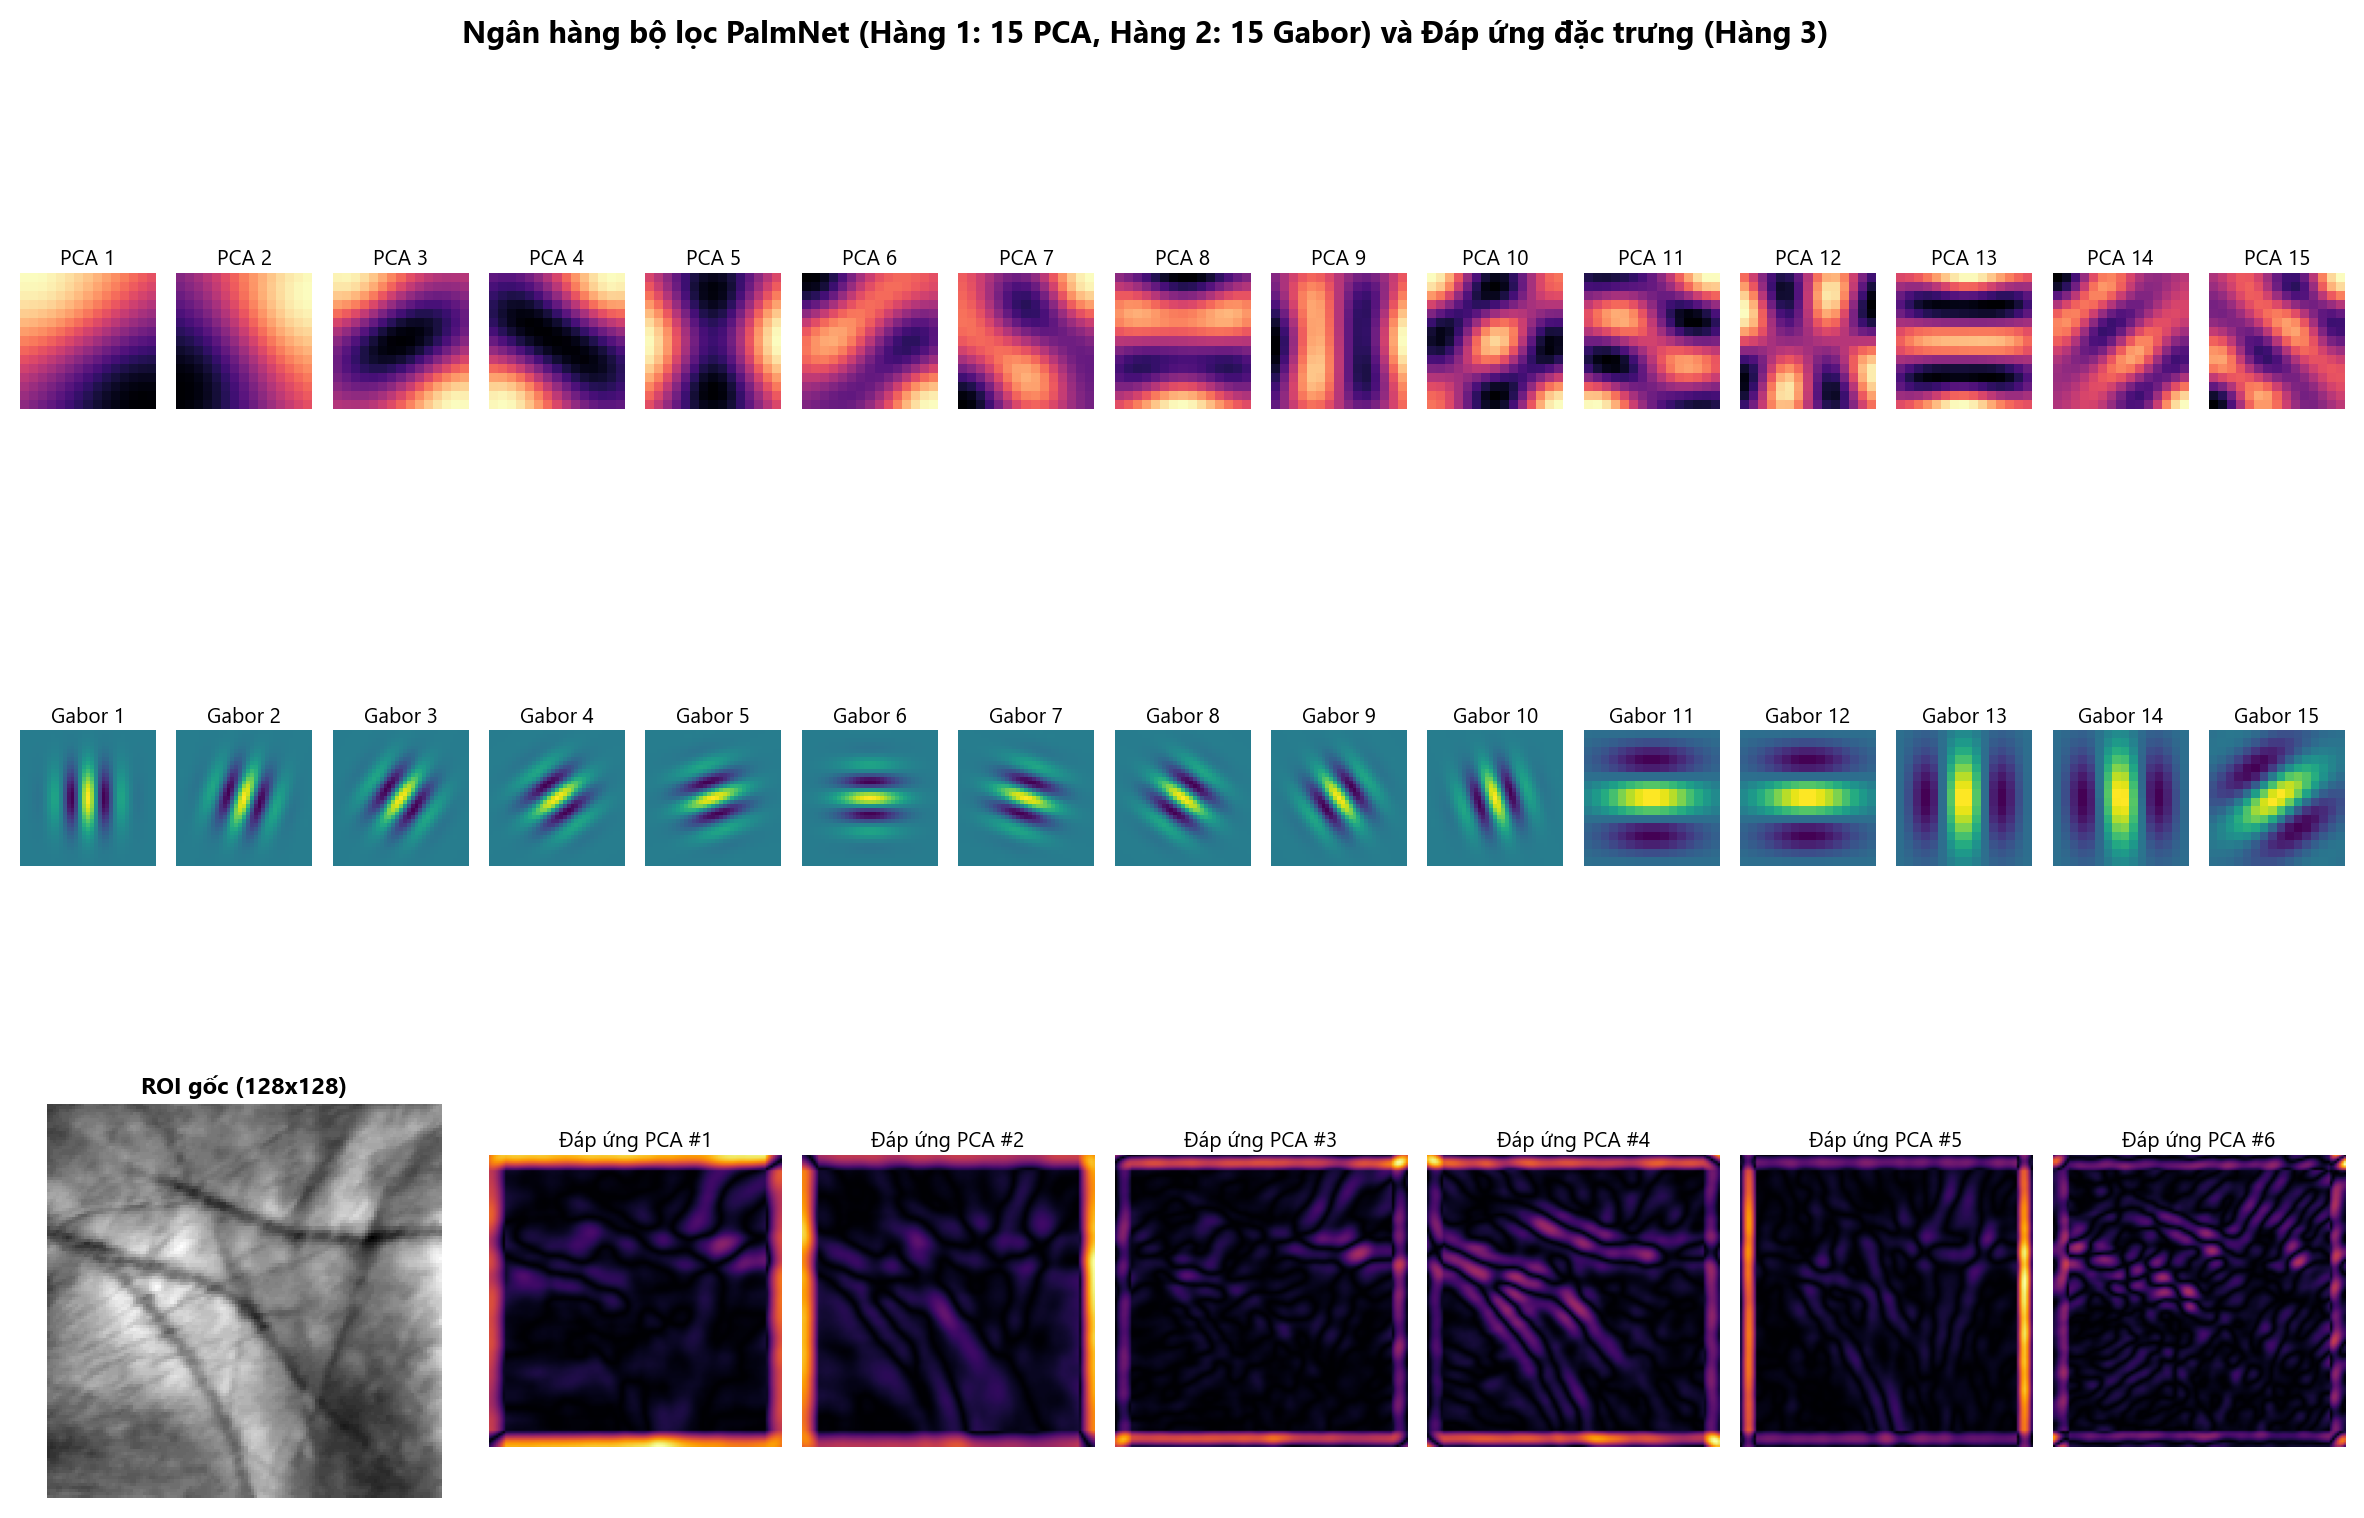

In [3]:
ckpt_path = ROOT / 'artifacts/pretrained/palmnet_pca_gabor_session1.pt'
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    pca_w = ckpt['pca_weight'].numpy()[:, 0, :, :]
    gabor_k = [k.numpy() if isinstance(k, torch.Tensor) else k for k in ckpt['gabor_kernels']]

    sample_gray = cv2.imread(str(ROOT / 'data/raw/session1/00001.bmp'), cv2.IMREAD_GRAYSCALE)
    if sample_gray is None:
        sample_gray = np.full((128, 128), 128, dtype=np.uint8)

    fig = plt.figure(figsize=(15, 8.5), dpi=200)
    gs = fig.add_gridspec(3, 15, height_ratios=[1, 1.2, 1.3], hspace=0.35, wspace=0.15)

    for i in range(15):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(normalize(pca_w[i]), cmap='magma')
        ax.set_title(f'PCA {i+1}', fontsize=7.5, pad=3)
        ax.axis('off')

    for i in range(15):
        ax = fig.add_subplot(gs[1, i])
        ax.imshow(normalize(gabor_k[i]), cmap='viridis')
        ax.set_title(f'Gabor {i+1}', fontsize=7.5, pad=3)
        ax.axis('off')

    ax_orig = fig.add_subplot(gs[2, 0:3])
    ax_orig.imshow(sample_gray, cmap='gray')
    ax_orig.set_title('ROI gốc (128x128)', fontsize=8.5, fontweight='bold', pad=4)
    ax_orig.axis('off')

    t_gray = torch.from_numpy(sample_gray.astype(np.float32) / 255.0)[None, None, :, :]
    t_pca = torch.from_numpy(pca_w[:6, None, :, :].astype(np.float32))
    pca_resp = F.conv2d(t_gray, t_pca, padding=7)[0].numpy()

    for idx in range(6):
        ax = fig.add_subplot(gs[2, 3 + idx * 2 : 3 + (idx + 1) * 2])
        resp = np.abs(pca_resp[idx])
        ax.imshow(normalize(resp), cmap='inferno')
        ax.set_title(f'Đáp ứng PCA #{idx+1}', fontsize=7.5, pad=3)
        ax.axis('off')

    fig.suptitle('Ngân hàng bộ lọc PalmNet (Hàng 1: 15 PCA, Hàng 2: 15 Gabor) và Đáp ứng đặc trưng (Hàng 3)', fontsize=11, fontweight='bold', y=0.98)
    plt.show()
else:
    print('Checkpoint PalmNet không tồn tại tại:', ckpt_path)

## 3. Bản đồ kích hoạt vùng chú ý Grad-CAM trên ResNet18 (M4)

Kỹ thuật Grad-CAM (Gradient-weighted Class Activation Mapping) trích xuất gradient từ tầng tích chập cuối cùng (`layer4`) của mạng ResNet18 đối với danh tính Palm ID mục tiêu:
$$\alpha_k^c = \frac{1}{Z} \sum_{i} \sum_{j} \frac{\partial y^c}{\partial A_{i,j}^k}$$
$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$
Bản đồ kích hoạt cho thấy mạng tập trung vào các nếp vân chính trung tâm lòng bàn tay để đưa ra quyết định phân loại.

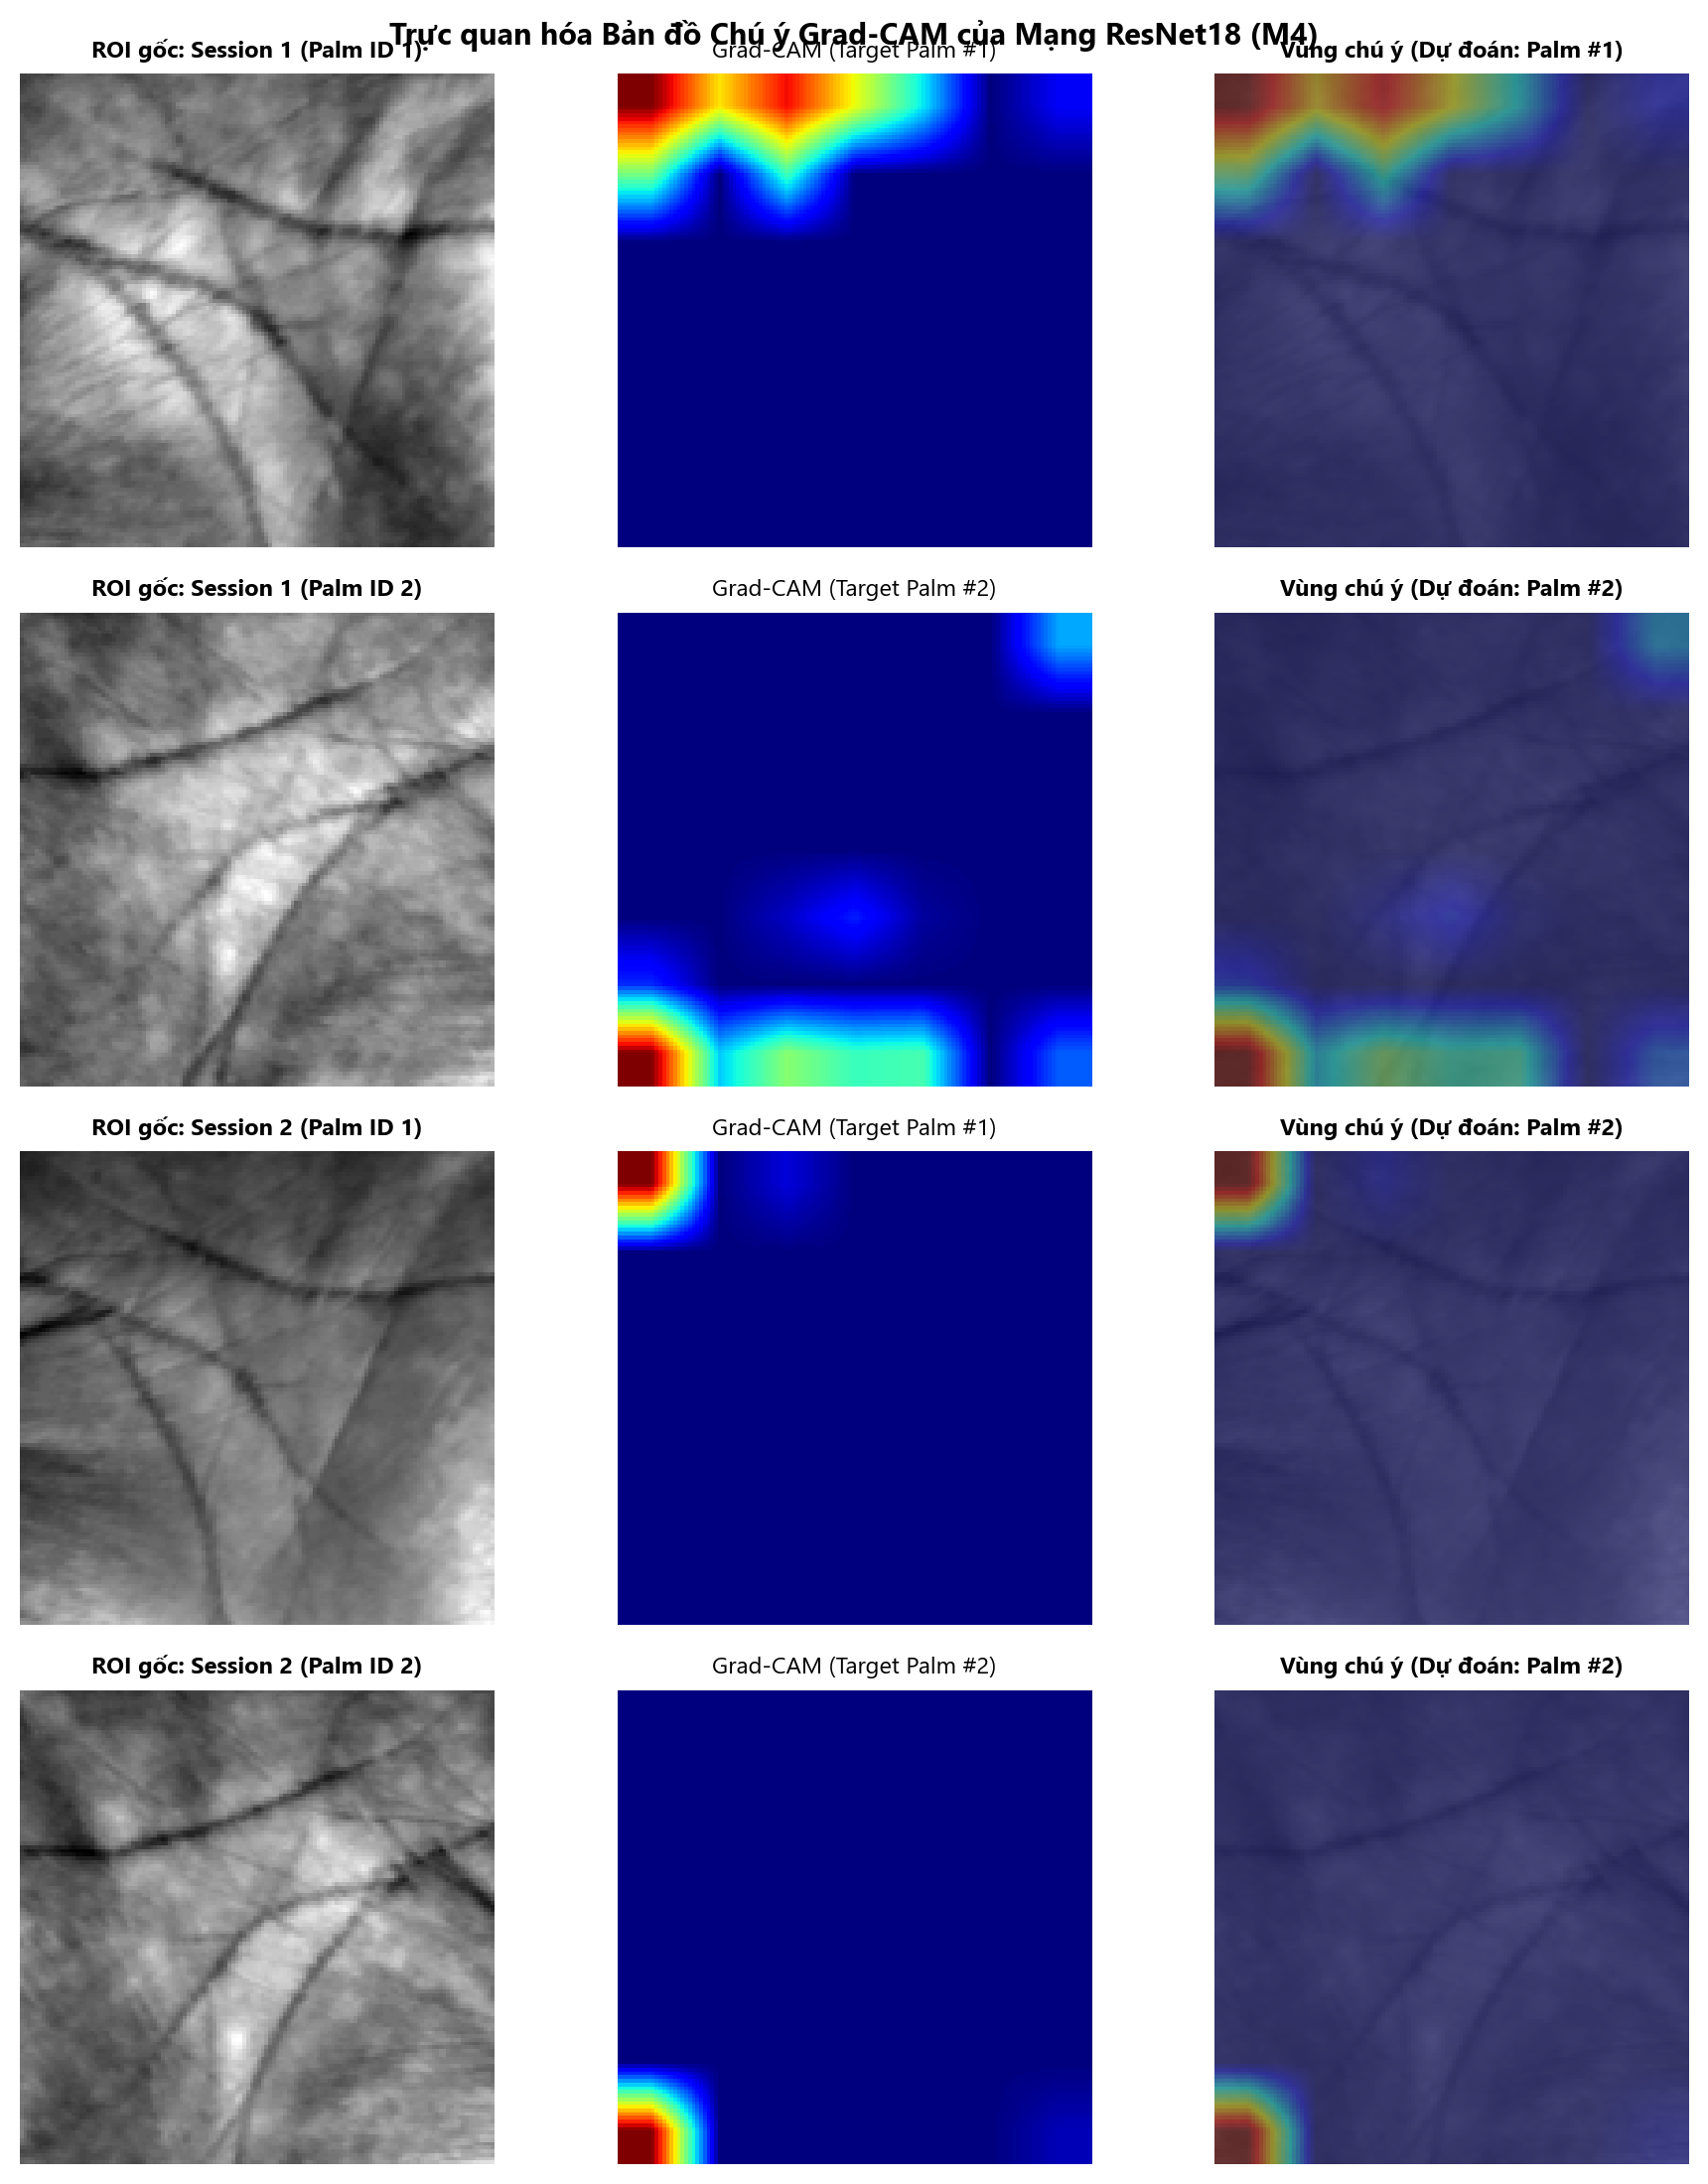

In [4]:
ckpt_cnn = ROOT / 'artifacts/resnet18_seed17.pth'
if ckpt_cnn.exists():
    model = make_resnet(600, 'none')
    ckpt = torch.load(ckpt_cnn, map_location='cpu')
    model.load_state_dict(ckpt['state_dict'] if 'state_dict' in ckpt else ckpt)
    model.eval()

    activations, gradients = [], []

    def f_hook(module, inp, out):
        activations.append(out)

    def b_hook(module, g_in, g_out):
        gradients.append(g_out[0])

    target_layer = model.layer4[1].conv2
    target_layer.register_forward_hook(f_hook)
    target_layer.register_full_backward_hook(b_hook)

    transform = preprocessing(training=False, size=224)

    test_samples = [
        (ROOT / 'data/raw/session1/00001.bmp', 'Session 1 (Palm ID 1)', 0),
        (ROOT / 'data/raw/session1/00011.bmp', 'Session 1 (Palm ID 2)', 1),
        (ROOT / 'data/raw/session2/00001.bmp', 'Session 2 (Palm ID 1)', 0),
        (ROOT / 'data/raw/session2/00011.bmp', 'Session 2 (Palm ID 2)', 1),
    ]

    fig, axes = plt.subplots(len(test_samples), 3, figsize=(9.5, 11), dpi=200)

    for row_idx, (path, label, target_class) in enumerate(test_samples):
        if not path.exists():
            continue
        gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
        img_rgb = cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB)

        tensor_img = transform(Image.fromarray(gray)).unsqueeze(0)
        activations.clear()
        gradients.clear()

        logits = model(tensor_img)
        pred_class = int(logits.argmax(dim=1).item())
        score = logits[0, target_class]

        model.zero_grad()
        score.backward()

        acts = activations[0].detach()[0]
        grads = gradients[0].detach()[0]
        weights = grads.mean(dim=(1, 2), keepdim=True)

        cam = F.relu((weights * acts).sum(dim=0)).numpy()
        cam = cv2.resize(cam, (128, 128))
        cam = normalize(cam)

        heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = np.uint8(0.6 * img_rgb + 0.4 * heatmap)

        axes[row_idx, 0].imshow(gray, cmap='gray')
        axes[row_idx, 0].set_title(f'ROI gốc: {label}', fontsize=8.5, fontweight='bold')
        axes[row_idx, 0].axis('off')

        axes[row_idx, 1].imshow(cam, cmap='jet')
        axes[row_idx, 1].set_title(f'Grad-CAM (Target Palm #{target_class+1})', fontsize=8.5)
        axes[row_idx, 1].axis('off')

        axes[row_idx, 2].imshow(overlay)
        axes[row_idx, 2].set_title(f'Vùng chú ý (Dự đoán: Palm #{pred_class+1})', fontsize=8.5, fontweight='bold')
        axes[row_idx, 2].axis('off')

    fig.tight_layout()
    fig.suptitle('Trực quan hóa Bản đồ Chú ý Grad-CAM của Mạng ResNet18 (M4)', fontsize=11, fontweight='bold', y=0.995)
    plt.show()
else:
    print('Checkpoint ResNet18 không tồn tại tại:', ckpt_cnn)